# Freight Rate Prediction – Exploration & Validation Walkthrough

Companion notebook for the Spotter ML assessment. **All logic lives in the Python modules**
(`features.py`, `model.py`); this notebook imports from them and presents the findings visually.
Reproduce the submission with `uv run python train.py`.

Sections: 1 data overview · 2 corrupted labels · 3 negative weights · 4 what drives the rate ·
5 time structure · 6 geography & unseen cities · 7 validation design · 8 final model · 9 prediction sanity · 10 December chart

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import Image, display
from features import load_raw, daily_market, city_lookup, corrupt_rate_mask, clean_weight, make_features, DIST_BINS
from model import FreightRateModel, SHAPE_FEATURES, LEVEL_MODES

# ---- chart style: recessive axes, thin marks, validated categorical palette ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # slots 1-3, validated all-pairs
EQUIP_COLOR = {"Dry Van": BLUE, "Reefer": ORANGE, "Flatbed": AQUA}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlesize": 12, "figure.dpi": 110})
pd.set_option("display.width", 160)

tr, va, dec = load_raw()
daily = daily_market(tr, va)       # daily market level, Jan-Dec (validation.csv carries Nov-Dec)
cities = city_lookup(tr, va)       # one coordinate pair per city
tr["rpm"] = tr.posted_rate / tr.distance
print(f"train {len(tr):,} rows {tr.date.min():%Y-%m-%d} → {tr.date.max():%Y-%m-%d}")
print(f"valid {len(va):,} rows {va.date.min():%Y-%m-%d} → {va.date.max():%Y-%m-%d}   (no target)")
print(f"december inputs: {len(dec)} rows, fixed lane, only the date changes")

train 48,000 rows 2025-01-01 → 2025-10-31
valid 12,000 rows 2025-11-01 → 2025-12-31   (no target)
december inputs: 31 rows, fixed lane, only the date changes


## 1. Data overview

The training window is January–October 2025 and the validation window is November–December 2025.
**The validation data is entirely in the future**, which makes this a forecasting problem and rules out random train/test splits.

In [2]:
overview = pd.DataFrame({
    "train": [len(tr), tr.date.nunique(), tr.pickup.nunique(), tr.equipment.nunique(), tr.weight.isna().sum(), tr.market_index.isna().sum()],
    "validation": [len(va), va.date.nunique(), va.pickup.nunique(), va.equipment.nunique(), va.weight.isna().sum(), va.market_index.isna().sum()],
}, index=["rows", "distinct dates", "pickup cities", "equipment types", "missing weight", "missing market_index"])
display(overview)
display(tr.head(3))

,train,validation
rows,48000,12000
distinct dates,304,61
pickup cities,64,72
equipment types,3,3
missing weight,300,165
missing market_index,374,249


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rpm
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,2.352935
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,2.424135
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1.862513


## 2. The target and its corrupted labels

Rate per mile is the natural unit. Genuine loads sit between roughly $1.7 and $3.2 per mile.
A thin tail of rows sits at **3–5× or ~0.2×** the typical rate for the same equipment and distance bucket; those are planted
errors, not market prices. `corrupt_rate_mask` flags a row when its rate is below half or above double the bucket median.

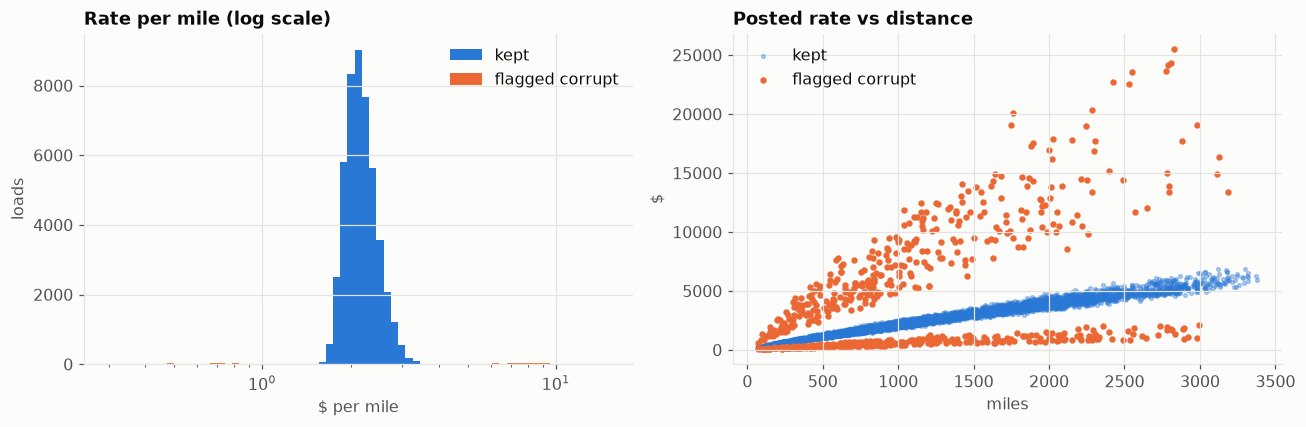

flagged 677 of 48,000 training rows (1.41%); they are dropped from training only


In [3]:
corrupt = corrupt_rate_mask(tr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(0.3), np.log10(15), 70)
ax[0].hist(tr.rpm[~corrupt], bins=bins, color=BLUE, label="kept")
ax[0].hist(tr.rpm[corrupt], bins=bins, color=ORANGE, label="flagged corrupt")
ax[0].set_xscale("log"); ax[0].set_title("Rate per mile (log scale)"); ax[0].set_xlabel("$ per mile"); ax[0].set_ylabel("loads")
ax[0].legend(frameon=False)
s = tr.sample(6000, random_state=0)
ax[1].scatter(s.distance[~corrupt[s.index]], s.posted_rate[~corrupt[s.index]], s=6, color=BLUE, alpha=.35, label="kept")
ax[1].scatter(tr.distance[corrupt], tr.posted_rate[corrupt], s=10, color=ORANGE, label="flagged corrupt")
ax[1].set_title("Posted rate vs distance"); ax[1].set_xlabel("miles"); ax[1].set_ylabel("$"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"flagged {corrupt.sum()} of {len(tr):,} training rows ({corrupt.mean():.2%}); they are dropped from training only")

## 3. Negative weights are sign flips

292 training rows carry a negative weight. The magnitudes mirror the positive distribution exactly, so the fix is `abs(weight)`
rather than dropping the rows. The same fix is applied to the 145 affected validation rows.

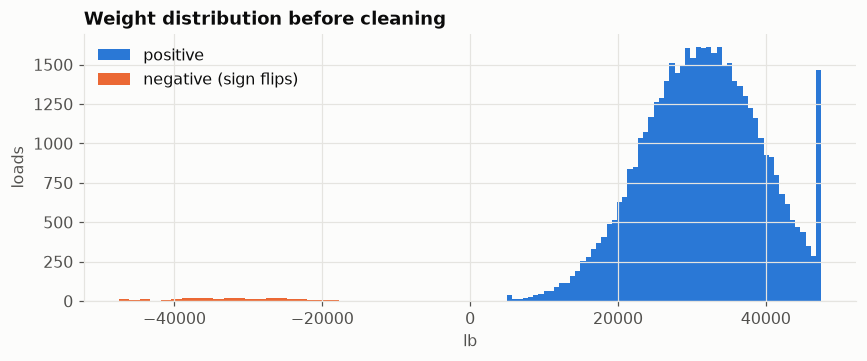

negative weights: train 292 | validation 145


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
w = tr.weight.dropna()
ax.hist(w[w > 0], bins=60, color=BLUE, label="positive")
ax.hist(w[w <= 0], bins=30, color=ORANGE, label="negative (sign flips)")
ax.set_title("Weight distribution before cleaning"); ax.set_xlabel("lb"); ax.set_ylabel("loads"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("negative weights: train", (tr.weight <= 0).sum(), "| validation", (va.weight <= 0).sum())

## 4. What drives the rate

Distance explains ~90% of the variance on its own, but **rate per mile is not constant**: short hauls cost far more per mile.
Equipment adds a multiplicative premium (Reefer > Flatbed > Dry Van) and heavier loads pay slightly more.
These multiplicative effects are why the model is fitted to `log(rate)`.

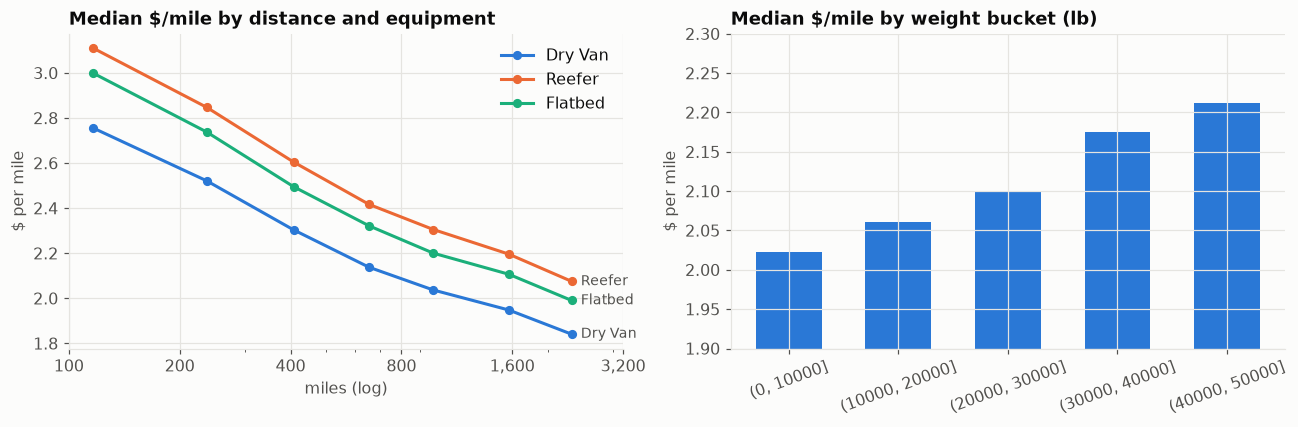

In [5]:
clean = tr[~corrupt].copy()
clean["dist_bin"] = pd.cut(clean.distance, DIST_BINS)
mid = clean.groupby("dist_bin", observed=True).distance.median()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for eq, col in EQUIP_COLOR.items():
    m = clean[clean.equipment == eq].groupby("dist_bin", observed=True).rpm.median()
    ax[0].plot(mid.loc[m.index], m.values, marker="o", markersize=5, color=col, label=eq)
    ax[0].annotate(eq, (mid.loc[m.index].iloc[-1], m.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax[0].set_xscale("log"); ax[0].set_xticks([100, 200, 400, 800, 1600, 3200]); ax[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}")); ax[0].xaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_title("Median $/mile by distance and equipment"); ax[0].set_xlabel("miles (log)"); ax[0].set_ylabel("$ per mile")
ax[0].legend(frameon=False, loc="upper right")
wb = clean.groupby(pd.cut(clean.weight, [0, 10000, 20000, 30000, 40000, 50000]), observed=True).rpm.median()
ax[1].bar([str(i) for i in wb.index], wb.values, color=BLUE, width=.6)
ax[1].set_ylim(1.9, 2.3); ax[1].set_title("Median $/mile by weight bucket (lb)"); ax[1].set_ylabel("$ per mile"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 5. Time structure

Rates rose from January to a June peak and eased in late summer. `market_index` is a **daily market signal**
(its within-day spread is one seventh of its yearly spread) and it moves with rates — but notice September–October:
the index fell back to January levels while rates did not. That shift is why the index turned out to be a poor forecasting input (section 7).
Because `validation.csv` carries the index for every November–December load, the daily series is known for the whole forecast window.

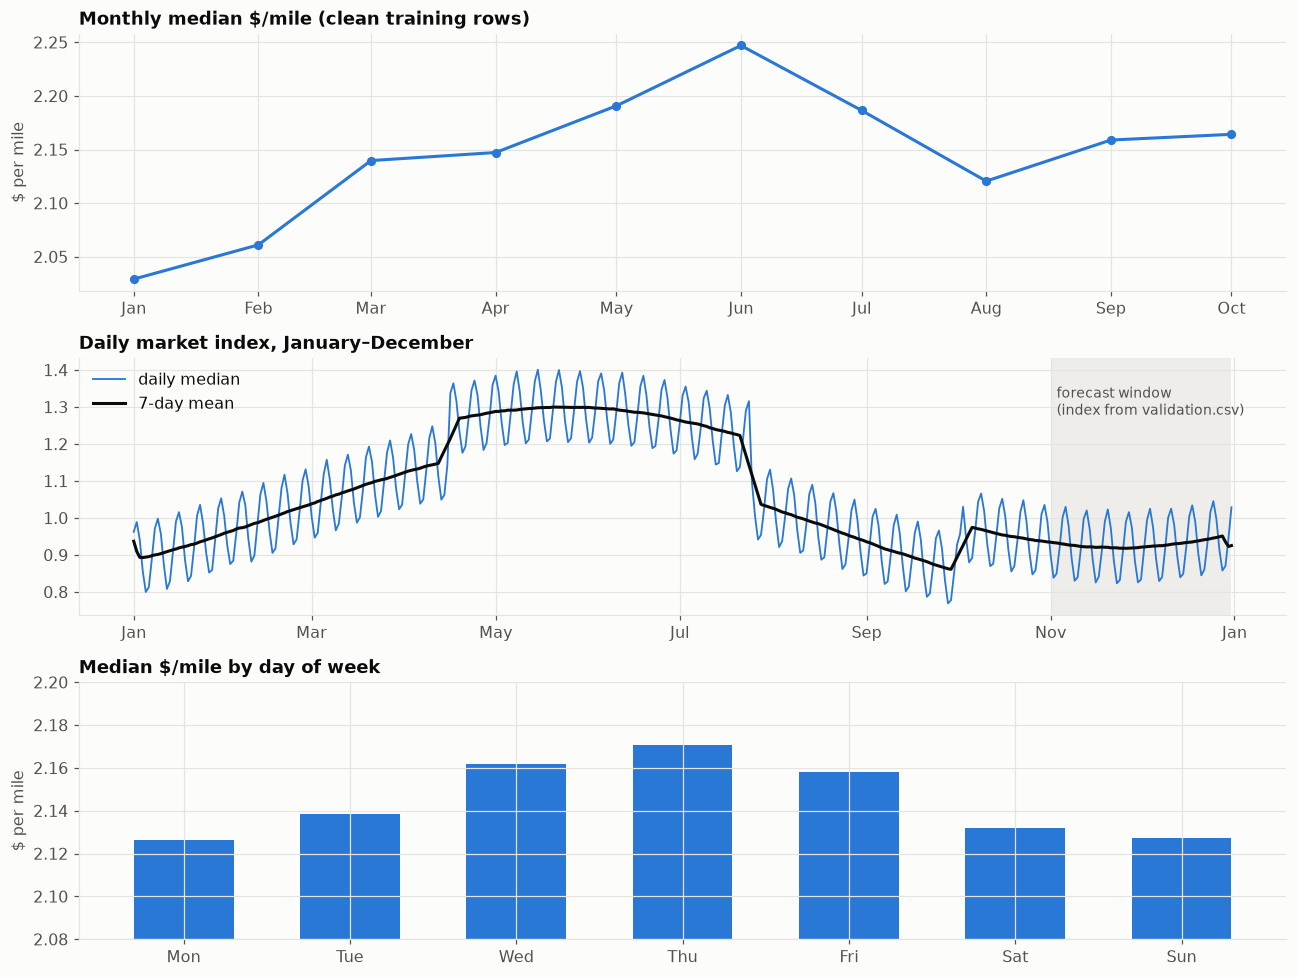

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(12, 9))
monthly = clean.groupby(clean.date.dt.to_period("M")).rpm.median()
ax[0].plot(monthly.index.to_timestamp(), monthly.values, marker="o", markersize=5, color=BLUE)
ax[0].set_title("Monthly median $/mile (clean training rows)"); ax[0].set_ylabel("$ per mile")
ax[1].plot(daily.index, daily.mi_daily, color=BLUE, linewidth=1.2, label="daily median")
ax[1].plot(daily.index, daily.mi_roll7, color=INK, linewidth=2, label="7-day mean")
ax[1].axvspan(pd.Timestamp("2025-11-01"), daily.index.max(), color=GRID, alpha=.6, lw=0)
ax[1].text(pd.Timestamp("2025-11-03"), daily.mi_daily.max() * .97, "forecast window\n(index from validation.csv)", color=INK2, fontsize=9, va="top")
ax[1].set_title("Daily market index, January–December"); ax[1].legend(frameon=False, loc="upper left")
dow = clean.groupby(clean.date.dt.dayofweek).rpm.median()
ax[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color=BLUE, width=.6)
ax[2].set_ylim(2.08, 2.2); ax[2].set_title("Median $/mile by day of week"); ax[2].set_ylabel("$ per mile")
for a in ax[:2]: a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()

## 6. Geography and unseen cities

Eight validation cities never appear in training, affecting ~12% of the rows to be scored.
The model therefore learns geography from **coordinates** (lat/lon, deltas, straight-line distance), never from city names.

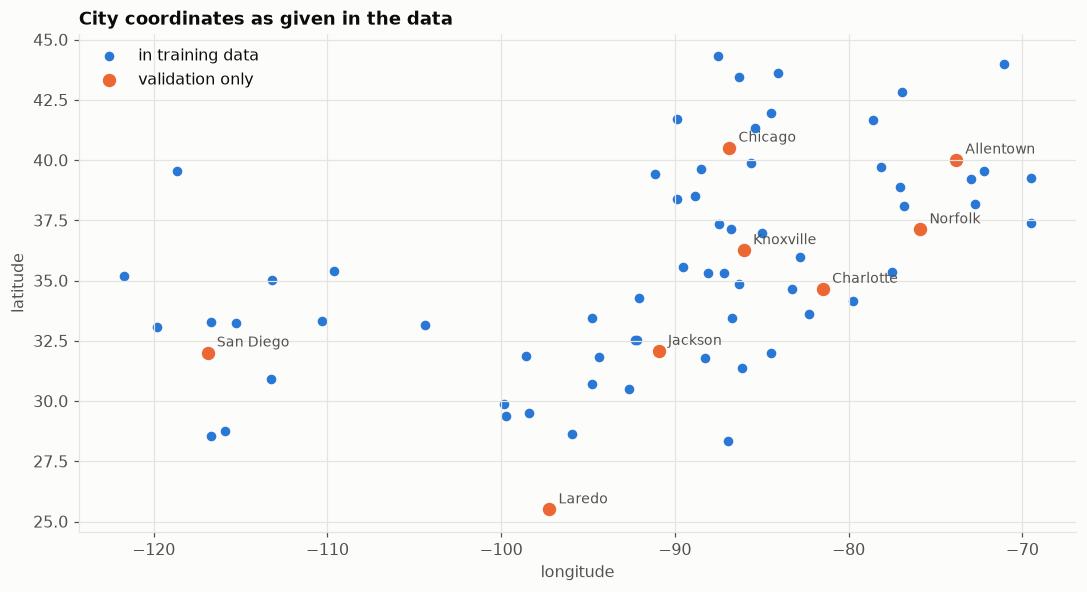

unseen cities: Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego
validation rows touching them: 1,447 (12.1%)


In [7]:
train_cities = set(tr.pickup) | set(tr.delivery)
unseen = sorted((set(va.pickup) | set(va.delivery)) - train_cities)
touch = va.pickup.isin(unseen) | va.delivery.isin(unseen)
fig, ax = plt.subplots(figsize=(10, 5.5))
seen = cities[cities.index.isin(train_cities)]; new = cities[cities.index.isin(unseen)]
ax.scatter(seen.lon, seen.lat, s=28, color=BLUE, label="in training data")
ax.scatter(new.lon, new.lat, s=60, color=ORANGE, label="validation only")
for c, r in new.iterrows(): ax.annotate(c, (r.lon, r.lat), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK2)
ax.set_title("City coordinates as given in the data"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("unseen cities:", ", ".join(unseen)); print(f"validation rows touching them: {touch.sum():,} ({touch.mean():.1%})")

## 7. Validation design: rolling-origin forecasting

Every experiment trains on the first *N* months and predicts the **next two**, exactly like the real task (train Jan–Oct, predict Nov–Dec).
Three cutoffs are used so a decision never rests on one lucky period. Errors are reported on clean test labels; corrupted labels add error no model can remove.

The two-stage model (`model.py`) separates the **shape** (how price depends on the load) from the daily **level** (how the market moves).
Four ways of projecting the level are compared, including none at all.

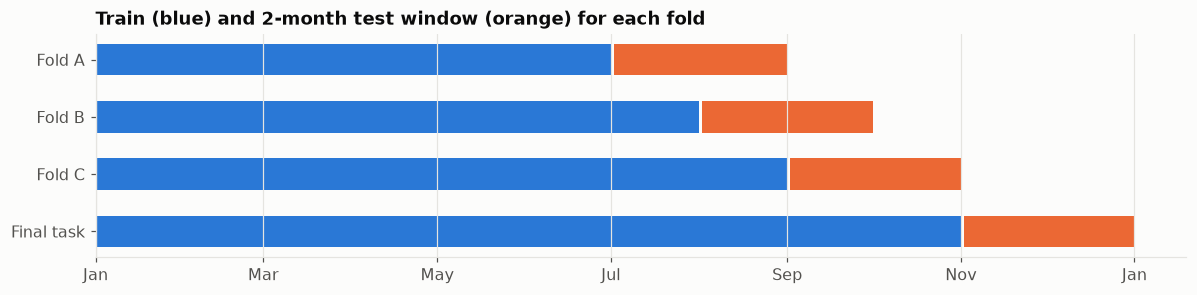

In [8]:
fig, ax = plt.subplots(figsize=(11, 2.8))
folds = [("Fold A", "2025-01-01", "2025-07-01", "2025-09-01"), ("Fold B", "2025-01-01", "2025-08-01", "2025-10-01"),
         ("Fold C", "2025-01-01", "2025-09-01", "2025-11-01"), ("Final task", "2025-01-01", "2025-11-01", "2026-01-01")]
for i, (name, s, c, e) in enumerate(folds):
    s, c, e = map(pd.Timestamp, (s, c, e))
    ax.barh(i, (c - s).days, left=mdates.date2num(s), color=BLUE, height=.55)
    ax.barh(i, (e - c).days - 1, left=mdates.date2num(c) + 1, color=ORANGE, height=.55)
ax.set_yticks(range(4)); ax.set_yticklabels([f[0] for f in folds]); ax.invert_yaxis(); ax.xaxis_date(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Train (blue) and 2-month test window (orange) for each fold")
plt.tight_layout(); plt.show()

fold,A Jul–Aug,B Aug–Sep,C Sep–Oct
level strategy,,,
mi_t_frozen,130.6,59.8,50.5
mi_t_trend,176.3,60.9,49.1
none,54.7,53.4,42.8
recent,88.7,79.3,43.3


,MAE,MAPE%,bias%
level strategy,,,
none,50.30,2.15,-0.27
recent,70.45,2.95,1.82
mi_t_frozen,80.33,3.37,1.64
mi_t_trend,95.43,4.01,2.68


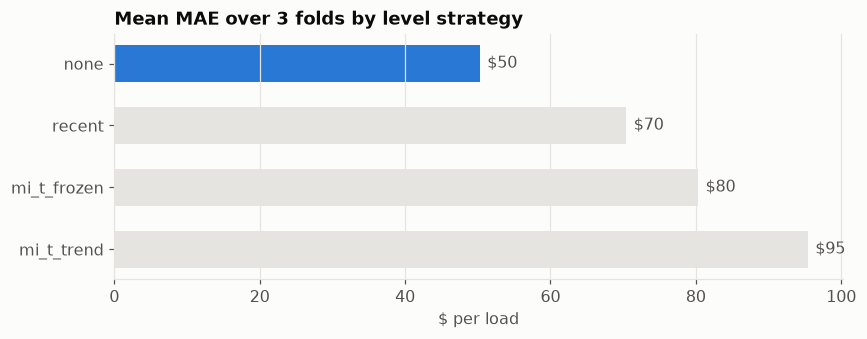

In [9]:
rows = []
for fold, cut in {"A Jul–Aug": "2025-07-01", "B Aug–Sep": "2025-08-01", "C Sep–Oct": "2025-09-01"}.items():
    cut = pd.Timestamp(cut)
    train_f = tr[tr.date < cut]
    test_f = tr[(tr.date >= cut) & (tr.date < cut + pd.DateOffset(months=2)) & ~corrupt]
    y = test_f.posted_rate.values
    for mode in LEVEL_MODES:
        p = FreightRateModel(level=mode).fit(train_f, daily, cities).predict(test_f)
        e = p - y
        rows.append({"fold": fold, "level strategy": mode, "MAE": np.abs(e).mean(), "MAPE%": 100 * np.mean(np.abs(e) / y), "bias%": 100 * np.mean(e / y)})
res = pd.DataFrame(rows)
display(res.pivot(index="level strategy", columns="fold", values="MAE").round(1))
summary = res.groupby("level strategy")[["MAE", "MAPE%", "bias%"]].mean().sort_values("MAE").round(2)
display(summary)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(summary.index, summary.MAE, color=[BLUE if i == "none" else GRID for i in summary.index], height=.6)
for i, v in enumerate(summary.MAE): ax.text(v + 1, i, f"${v:.0f}", va="center", color=INK2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_title("Mean MAE over 3 folds by level strategy"); ax.set_xlabel("$ per load")
plt.tight_layout(); plt.show()

**Result:** the level-free model wins every fold (mean MAE ≈ $50, bias ≈ 0). The index coefficient flipped sign between folds,
so the index→rate relationship is too unstable to extrapolate. The final model carries the average level of the whole training window.

## 8. Final model: what it relies on

Shape model = `HistGradientBoostingRegressor` on `log(rate)`, 15 load-level features, no calendar or trend inputs.
Below: permutation importance and predicted-vs-actual on the Sep–Oct holdout (model trained on Jan–Aug).

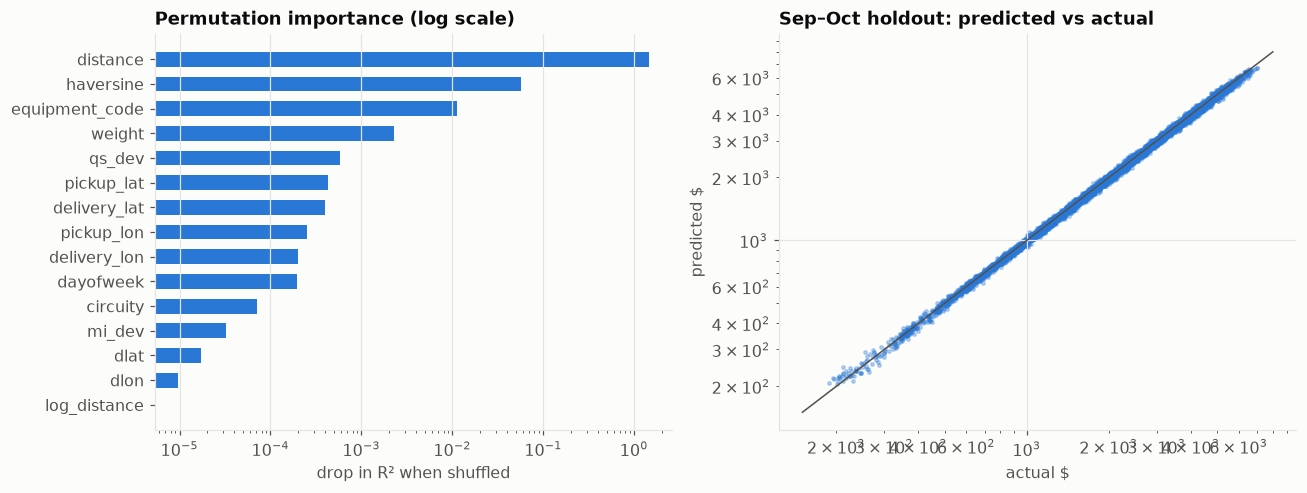

holdout MAE $42.8 | MAPE 1.83% | bias -0.62%


In [10]:
from sklearn.inspection import permutation_importance
from model import _prep
cut = pd.Timestamp("2025-09-01")
m = FreightRateModel(level="none").fit(tr[tr.date < cut], daily, cities)
hold = tr[(tr.date >= cut) & ~corrupt]
fh = _prep(hold, daily, cities)
imp = permutation_importance(m.shape_, fh[SHAPE_FEATURES], np.log(hold.posted_rate), n_repeats=3, random_state=0)
imp = pd.Series(imp.importances_mean, index=SHAPE_FEATURES).sort_values()
pred = m.predict(hold)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].barh(imp.index, imp.values, color=BLUE, height=.6); ax[0].set_xscale("log"); ax[0].grid(axis="y", visible=False)
ax[0].set_title("Permutation importance (log scale)"); ax[0].set_xlabel("drop in R² when shuffled")
ax[1].scatter(hold.posted_rate, pred, s=5, color=BLUE, alpha=.3)
lim = [150, 8000]; ax[1].plot(lim, lim, color=INK2, linewidth=1); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Sep–Oct holdout: predicted vs actual"); ax[1].set_xlabel("actual $"); ax[1].set_ylabel("predicted $")
plt.tight_layout(); plt.show()
e = pred - hold.posted_rate.values
print(f"holdout MAE ${np.abs(e).mean():.1f} | MAPE {100*np.mean(np.abs(e)/hold.posted_rate):.2f}% | bias {100*np.mean(e/hold.posted_rate):+.2f}%")

## 9. Prediction sanity checks

The final model is refitted on **all** clean Jan–Oct rows (more recent data is the most valuable for a forecast) and run on the
12,000 validation loads. The predicted rate-per-mile distribution should look like the training one, per equipment, and unseen cities
should not be priced differently from the rest.

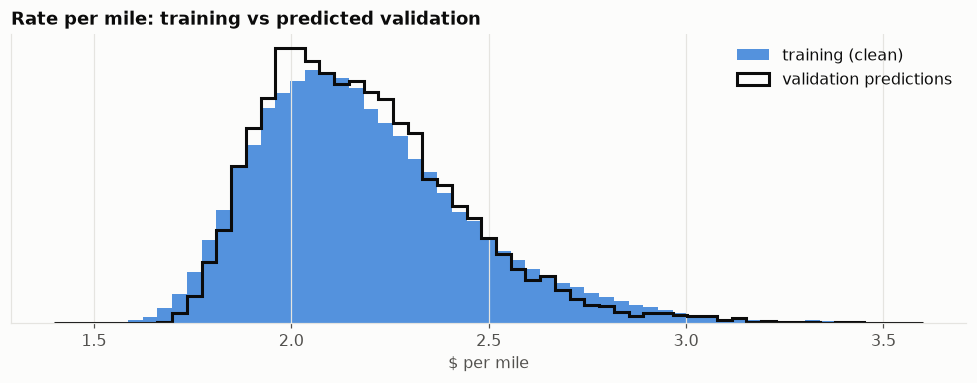

,train median $/mile,predicted median $/mile
Dry Van,2.046,2.042
Flatbed,2.220,2.210
Reefer,2.312,2.294


unseen-city rows: 2.141 $/mile | other rows: 2.145 $/mile
shape GBM on 15 features, 677 corrupt rows dropped; level[none]: resid = -0.1342 + 0.1011*mi + 0.0163*(t/100d); recent 8-week level = +0.56%


In [11]:
final = FreightRateModel(level="none").fit(tr, daily, cities)
va_pred = final.predict(va)
va_rpm = va_pred / va.distance.values
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(1.4, 3.6, 60)
ax.hist(clean.rpm, bins=bins, density=True, color=BLUE, alpha=.8, label="training (clean)")
ax.hist(va_rpm, bins=bins, density=True, histtype="step", color=INK, linewidth=2, label="validation predictions")
ax.set_title("Rate per mile: training vs predicted validation"); ax.set_xlabel("$ per mile"); ax.set_yticks([]); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"train median $/mile": clean.groupby("equipment").rpm.median(),
                      "predicted median $/mile": pd.Series(va_rpm).groupby(va.equipment.values).median()}).round(3))
print(f"unseen-city rows: {np.median(va_rpm[touch]):.3f} $/mile | other rows: {np.median(va_rpm[~touch]):.3f} $/mile")
print(final.describe())

## 10. December chart: Lexington → Fort Wayne, Dry Van, 32,000 lb

Only the date changes across the 31 rows. With no time-level term, the only date-driven input is **day of week**, so the
prediction is a weekly cycle (Thursday high, Sunday low) around the lane's recent level. The historical Dry Van loads on this lane
ran $758–$934 and averaged $820 in Sep–Oct.

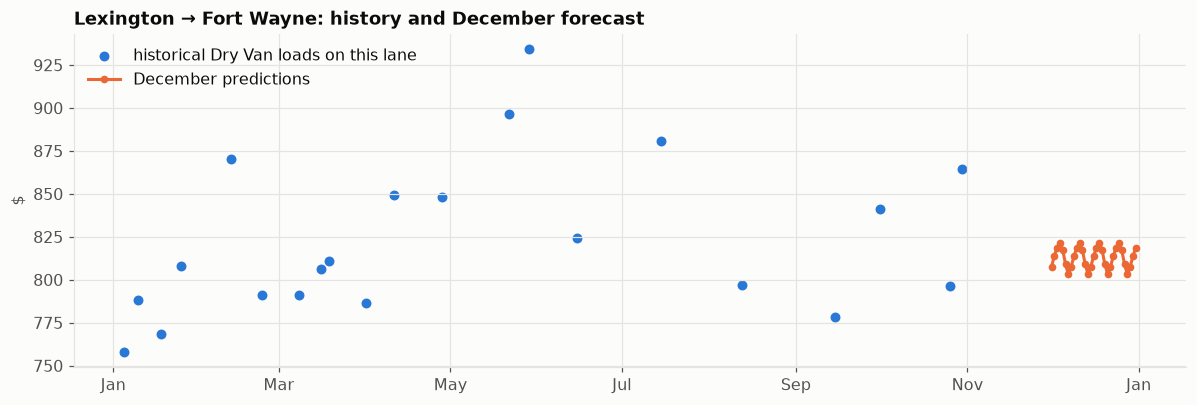

December predictions $803–$822, mean $813


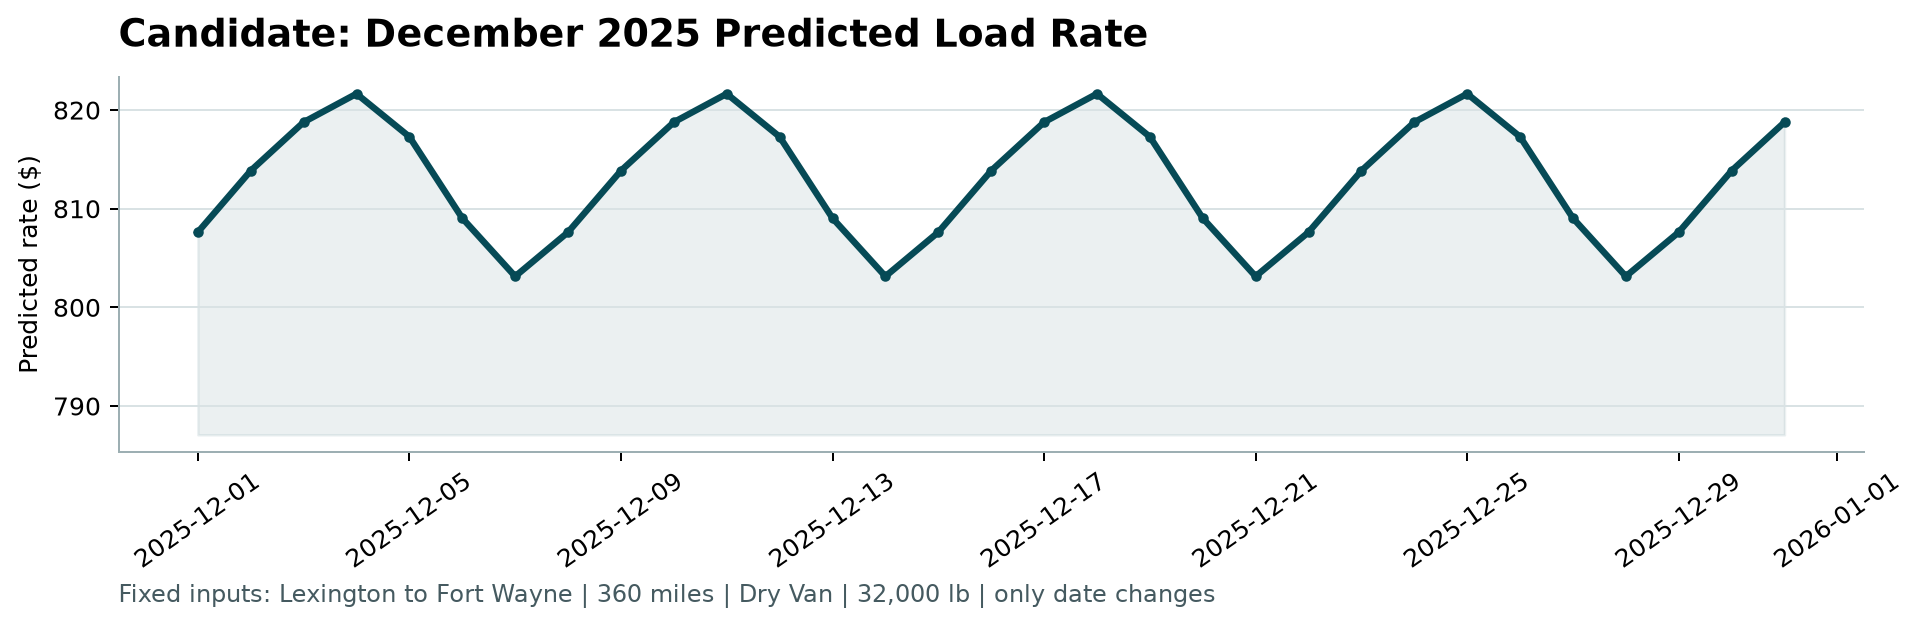

In [12]:
dec_pred = final.predict(dec)
lane = clean[(clean.pickup == "Lexington") & (clean.delivery == "Fort Wayne") & (clean.equipment == "Dry Van")]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.scatter(lane.date, lane.posted_rate, s=30, color=BLUE, label="historical Dry Van loads on this lane")
ax.plot(dec.date, dec_pred, color=ORANGE, marker="o", markersize=4, label="December predictions")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.set_ylabel("$"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Lexington → Fort Wayne: history and December forecast")
plt.tight_layout(); plt.show()
print(f"December predictions ${dec_pred.min():.0f}–${dec_pred.max():.0f}, mean ${dec_pred.mean():.0f}")
display(Image("scorer_results/candidate_december.png", width=900))

## Conclusions

- **Problem type:** a two-month forecast, so all validation is forward in time with three rolling folds.
- **Data issues fixed:** ~1.4% corrupted rates dropped from training; negative weights made positive; missing market index filled from the daily median.
- **Model:** gradient boosting on `log(rate)` with coordinate-based geography, so eight never-seen cities are handled.
- **Key decision:** the market index, despite a 0.64 in-sample correlation with daily rates, hurts out-of-sample forecasts because its relationship to rates shifted in late summer. The final model carries no time-level term. Mean rolling-origin MAE ≈ $50 (2.1%), bias ≈ 0.
- **Limitations:** week-scale rate bumps of 1–2% are unpredictable from the inputs; late-December holiday effects are not in the training window; corrupted labels in the hidden answers cap any achievable score.